# Lab 3C — From temporal features to decisions

**Audience:** Beginner Strategic Engineering MSc students  
**Lecture scope:** Slides **96–168** (conventional supervised models, DTW, fair comparison)  
**Suggested duration:** 120–150 minutes (Sections A + B + C); optional interpretation questions can be completed afterward.  
**Version:** Teacher solution

## Engineering challenge
Use **simple, interpretable models** before introducing complex temporal networks. This lab contains three small experiments:

1. **Forecasting** hourly energy demand: persistence → Ridge on lags → Ridge with more features → gradient boosting.
2. **Machine condition classification** from vibration-window features: majority → logistic regression → decision tree → random forest → boosting.
3. **Sequence similarity:** Euclidean versus DTW in a 1-nearest-neighbour classifier for short transients.

All data are **synthetic** and generated inside this notebook. The tasks are separate; their scores must not be compared with one another. The goal is a **fair engineering comparison**, not an impressive leaderboard.

**Key rule:** Use only inputs available at the prediction time. Validation is for selection; test is for final evaluation. In classification, group all windows from the same recording run in one partition.


## 0. Setup — run this cell first
Packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`. No network or external dataset is required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import train_test_split
from time import perf_counter

SEED = 23
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (9, 3.3), 'axes.grid': True})
print('Libraries ready; random seed:', SEED)


Libraries ready; random seed: 23


# A. Next-hour energy-demand forecasting (about 35 minutes)

**Decision at time t:** forecast energy demand at **t+1**. Past demand and current temperature are observed; next-hour clock/calendar are known. **The actual temperature at t+1 is not available**.

We first construct one synthetic *continuous* hourly recording. Inspect one week of data.

   time  demand  temperature  hour  weekday
0     0   52.05        12.89     0        0
1     1   54.48        12.66     1        0
2     2   51.60        12.99     2        0


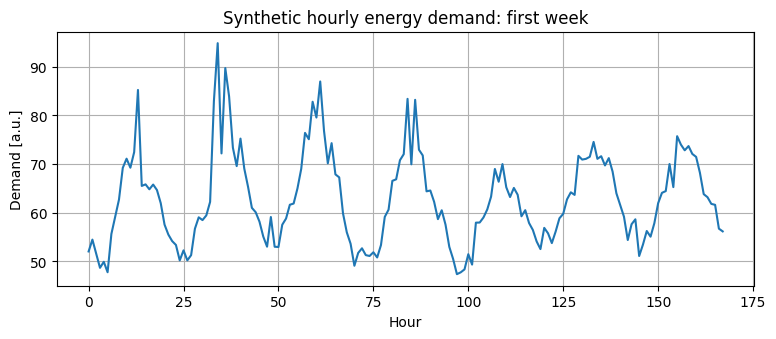

In [2]:
# Synthetic hourly demand, temperature and calendar data (one continuous recording).
# The synthetic nonlinear thermal term gives tree-based methods something to learn.
n_hours = 24 * 84
hour_idx = np.arange(n_hours)
hour = hour_idx % 24
weekday = (hour_idx // 24) % 7
is_weekend = (weekday >= 5).astype(int)
ambient = 19 + 7*np.sin(2*np.pi*(hour-6)/24) + 2*np.sin(2*np.pi*hour_idx/(24*7)) + rng.normal(0, 1.6, n_hours)
noise = np.zeros(n_hours)
for j in range(1, n_hours):
    noise[j] = 0.65*noise[j-1] + rng.normal(0, 1.6)
demand = (48 + 0.65*ambient + 5*np.sin(2*np.pi*(hour-8)/24)
          + 3.5*is_weekend + 0.45*np.maximum(ambient-23,0)**2
          + 0.0015*hour_idx + noise)
raw = pd.DataFrame({'time':hour_idx, 'demand':demand, 'temperature':ambient,
                    'hour':hour, 'weekday':weekday})
print(raw.head(3).round(2))
plt.plot(raw['time'][:24*7], raw['demand'][:24*7]); plt.xlabel('Hour'); plt.ylabel('Demand [a.u.]'); plt.title('Synthetic hourly energy demand: first week'); plt.show()


### A1. Construct a causal feature table
Complete the missing expressions. For each forecasting origin *t*, use demand values at *t* or earlier. Define the **target** as demand at *t+1*. Next-hour calendar variables are known in advance; **do not use actual next-hour temperature**.

**Question:** Would computing `data['demand'].shift(-1)` as an input feature be valid? Why not?

In [3]:
# Every row represents a decision made at time t to predict demand at t+1.
# Rolling statistics include t and earlier observations ONLY.
data = raw.copy()
for lag in [0, 1, 2, 24]:
    data[f'demand_lag_{lag}'] = data['demand'].shift(lag)
data['rolling_mean_24'] = data['demand'].rolling(24).mean()
data['recent_change_6'] = data['demand'] - data['demand'].shift(5)
data['temperature_now'] = data['temperature']
# Next-hour clock/calendar are known in advance; actual next-hour temperature is not.
next_hour = (data['hour'] + 1) % 24
next_weekday = (data['weekday'] + (data['hour']==23).astype(int)) % 7
data['next_hour_sin'] = np.sin(2*np.pi*next_hour/24)
data['next_hour_cos'] = np.cos(2*np.pi*next_hour/24)
data['next_is_weekend'] = (next_weekday >= 5).astype(int)
data['target_next'] = data['demand'].shift(-1)
data = data.dropna().reset_index(drop=True)
lag_cols = ['demand_lag_0', 'demand_lag_1','demand_lag_2','demand_lag_24']
full_cols = lag_cols + ['rolling_mean_24','recent_change_6','temperature_now','next_hour_sin','next_hour_cos','next_is_weekend']
assert 'temperature_next' not in full_cols
print('One feature row, ending at time t:')
print(data[full_cols + ['target_next']].head(2).round(2))


One feature row, ending at time t:
   demand_lag_0  demand_lag_1  ...  next_is_weekend  target_next
0         50.21         53.38  ...                0        52.27
1         52.27         50.21  ...                0        50.22

[2 rows x 11 columns]


**Answer:** `shift(-1)` is appropriate for the *target* column only. Using it as an input reveals the value to predict. A rolling mean is valid when it includes only observations through the forecast origin.

### A2. Chronological train / validation / test
Never shuffle overlapping windows or select models using the test set.

In [4]:
# Chronological partitions of prediction targets; windows do not cross into future inputs.
n = len(data)
train = data.iloc[:int(n*0.60)]
val   = data.iloc[int(n*0.60):int(n*0.80)]
test  = data.iloc[int(n*0.80):]
print('Train / validation / test:', len(train), len(val), len(test))
print('Time indices:', (train.time.min(),train.time.max()), (val.time.min(),val.time.max()), (test.time.min(),test.time.max()))
assert train.time.max() < val.time.min() < test.time.min()


Train / validation / test: 1194 398 399
Time indices: (np.int64(24), np.int64(1217)) (np.int64(1218), np.int64(1615)) (np.int64(1616), np.int64(2014))


### A3. Regression baseline ladder
Compare **the same validation targets**:

- Persistence: predict demand[t+1] = demand[t].
- Ridge on four selected lags: learned linear combination of past demand.
- Ridge on richer features: add rolling mean, recent change, current temperature, known calendar.
- Gradient boosting on the **same richer features**: test nonlinear model flexibility.

**Important experimental nuance:** Ridge/lags → Ridge/features changes **both representation and admissible information** (temperature and calendar), not solely representation. Ridge/features → Boosting/features changes the model while keeping the input set fixed.

**Task:** complete the training loop and construct a validation MAE table; report runtime too.

In [5]:
# The first two learned models differ in representation, not algorithm.
reg_models = {
    'Ridge / lags': (make_pipeline(StandardScaler(), Ridge(alpha=10)), lag_cols),
    'Ridge / features': (make_pipeline(StandardScaler(), Ridge(alpha=10)), full_cols),
    'Boosting / features': (HistGradientBoostingRegressor(max_iter=100, learning_rate=0.08, max_leaf_nodes=15, random_state=SEED), full_cols)
}
results_reg = []
val_reg_pred = {'Persistence': val['demand_lag_0'].to_numpy()}
results_reg.append({'Model':'Persistence','MAE':mean_absolute_error(val.target_next, val_reg_pred['Persistence']), 'Fit time [s]':0.0})
for name,(est,cols) in reg_models.items():
    start = perf_counter()
    est.fit(train[cols], train.target_next)
    dt = perf_counter()-start
    pred = est.predict(val[cols]); val_reg_pred[name] = pred
    results_reg.append({'Model':name,'MAE':mean_absolute_error(val.target_next,pred),'Fit time [s]':dt})
reg_report = pd.DataFrame(results_reg).sort_values('MAE')
print(reg_report.round(3).to_string(index=False))


              Model   MAE  Fit time [s]
   Ridge / features 2.356         0.003
Boosting / features 2.467         0.131
       Ridge / lags 2.890         0.005
        Persistence 3.230         0.000


**Check:** The best method is not predetermined. Inspect the observed validation MAEs before drawing any conclusion; changing random seeds or data generation can change the ranking.

**Visualization:** Compare actual validation demand with persistence and boosting over a short interval.

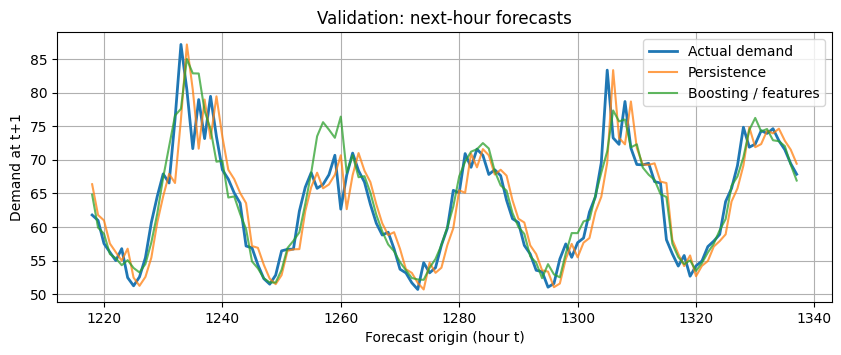

In [6]:
plt.figure(figsize=(10,3.5))
plt.plot(val.time.to_numpy()[:120], val.target_next.to_numpy()[:120], label='Actual demand', lw=2)
plt.plot(val.time.to_numpy()[:120], val_reg_pred['Persistence'][:120],label='Persistence',alpha=.75)
plt.plot(val.time.to_numpy()[:120], val_reg_pred['Boosting / features'][:120],label='Boosting / features',alpha=.75)
plt.xlabel('Forecast origin (hour t)'); plt.ylabel('Demand at t+1'); plt.title('Validation: next-hour forecasts'); plt.legend(); plt.show()


### A4. Freeze selection; evaluate on test
Choose the model with the best validation MAE *before* looking at the test. Report the selected model and the predeclared persistence reference on test. No hyperparameter changes after this point.

In [7]:
# Model selection uses validation only. Test stays untouched until this cell.
best_name = reg_report.iloc[0]['Model']
print('Selected using validation MAE:', best_name)
if best_name == 'Persistence':
    test_pred = test.demand_lag_0.to_numpy()
else:
    test_est, selected_cols = reg_models[best_name]
    test_pred = test_est.predict(test[selected_cols])
print('Selected model test MAE:', round(mean_absolute_error(test.target_next,test_pred),3))
print('Persistence test MAE:', round(mean_absolute_error(test.target_next,test.demand_lag_0),3))


Selected using validation MAE: Ridge / features
Selected model test MAE: 2.302
Persistence test MAE: 3.332


**Think and explain:**

1. Which comparison asks whether learned weights over history help?
2. Which comparison asks whether nonlinear relationships help?
3. Why must every model use the same forecast origin and horizon?
4. How would you design an additional ablation to separate **new input information** from **new derived features**?

**Suggested answers:** Ridge / features versus Ridge / lags isolates the value of adding engineered/context features **and additional admissible information** (temperature and calendar). To isolate only representation, both must have identical raw information; treating calendar/temperature as added information is a separate factor. Boosting / features versus Ridge / features isolates model flexibility while holding the feature set fixed. Train/validation/test use ordered target times. We never use actual temperature at t+1.

# B. Vibration-based fault classification (about 40 minutes)

**Decision:** classify a 2-second completed vibration window as `normal (0)` or `fault-like (1)`. Windows belonging to the **same recording run** are closely related: they must stay in the same partition. This is *offline window classification*, not forecasting. Full-window features are therefore allowed.

We intentionally create a minority fault class, so a majority-class predictor is an instructive reference.

Total windows: 480 Distinct recording runs: 160


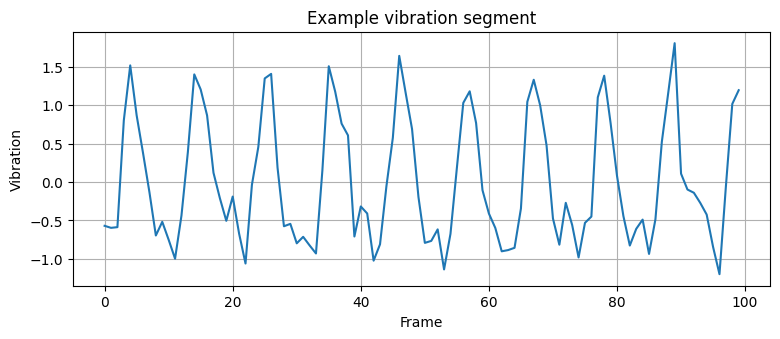

In [8]:
# Independent synthetic recording runs, with three related windows per run.
# Labels are illustrative: normal vs fault-like vibration.
FS = 100.0
L = 200
n_runs = 160
n_windows_per_run = 3
run_label = np.array([0]*110 + [1]*50)
class_rng = np.random.default_rng(104)
class_rng.shuffle(run_label)
recordings = []
for run_id, condition in enumerate(run_label):
    f0 = class_rng.normal(10.0, 0.35)
    base_amp = class_rng.uniform(.65,1.45)
    harmonic_amp = class_rng.normal(0.17 if condition==0 else 0.40, 0.065)
    high_amp = class_rng.normal(0.08 if condition==0 else 0.21,0.055)
    for j in range(n_windows_per_run):
        tt=np.arange(L)/FS
        phase=class_rng.uniform(0,2*np.pi)
        x = base_amp*np.sin(2*np.pi*f0*tt+phase)
        x += harmonic_amp*np.sin(2*np.pi*2*f0*tt + class_rng.uniform(0,2*np.pi))
        x += high_amp*np.sin(2*np.pi*35*tt + class_rng.uniform(0,2*np.pi))
        x += class_rng.normal(0,0.19,L)
        recordings.append({'run_id':run_id,'window_id':j,'label':condition,'signal':x})
print('Total windows:',len(recordings),'Distinct recording runs:',n_runs)
plt.plot(recordings[0]['signal'][:100]); plt.xlabel('Frame');plt.ylabel('Vibration');plt.title('Example vibration segment');plt.show()


### B1. Extract temporal and spectral features
The previous lab introduced RMS and relative frequency-band power. Complete the two relative-band power expressions. The classifier sees **a feature table**, not an ordered waveform.

In [9]:
def window_features(x, fs=FS):
    x=np.asarray(x, dtype=float)
    residual=x-np.mean(x)
    power=np.abs(np.fft.rfft(residual*np.hanning(len(x))))**2
    freq=np.fft.rfftfreq(len(x),d=1/fs)
    total=power[1:].sum()+1e-12
    rel_mid=power[(freq>=15)&(freq<30)].sum()/total
    rel_high=power[(freq>=30)&(freq<=50)].sum()/total
    rms=np.sqrt(np.mean(x*x))
    return {'rms':rms,'std':x.std(),'max_abs':np.abs(x).max(),
            'crest_factor':np.abs(x).max()/(rms+1e-12),
            'rel_mid':rel_mid,'rel_high':rel_high}
rows=[]
for rec in recordings:
    rows.append({'run_id':rec['run_id'],'label':rec['label'],**window_features(rec['signal'])})
feature_df=pd.DataFrame(rows)
feature_cols=['rms','std','max_abs','crest_factor','rel_mid','rel_high']
print(feature_df.groupby('label')[feature_cols].mean().round(3))


         rms    std  max_abs  crest_factor  rel_mid  rel_high
label                                                        
0      0.768  0.768    1.545          2.04    0.052     0.038
1      0.831  0.831    1.787          2.18    0.140     0.060


### B2. Split by recording run, not by window
Each `run_id` must belong to exactly one partition. This prevents a model from seeing almost-duplicate segments from the same run in both training and test.

In [10]:
# Split complete recording runs, NEVER related windows independently.
run_ids=np.arange(n_runs)
train_runs, leftover_runs = train_test_split(run_ids, test_size=0.40, random_state=SEED, stratify=run_label)
val_runs, test_runs = train_test_split(leftover_runs, test_size=0.50, random_state=SEED, stratify=run_label[leftover_runs])
train_c=feature_df[feature_df.run_id.isin(train_runs)]
val_c=feature_df[feature_df.run_id.isin(val_runs)]
test_c=feature_df[feature_df.run_id.isin(test_runs)]
assert set(train_c.run_id).isdisjoint(val_c.run_id)
assert set(train_c.run_id).isdisjoint(test_c.run_id)
assert set(val_c.run_id).isdisjoint(test_c.run_id)
print('Windows / recording runs per partition:')
for name, df in [('train',train_c),('validation',val_c),('test',test_c)]:
    print(f'{name:>10}: {len(df):>3} windows, {df.run_id.nunique():>3} runs; fault fraction {df.label.mean():.2f}')


Windows / recording runs per partition:
     train: 288 windows,  96 runs; fault fraction 0.31
validation:  96 windows,  32 runs; fault fraction 0.31
      test:  96 windows,  32 runs; fault fraction 0.31


### B3. Compare conventional classifiers
Run these five simple alternatives on the **same features and partitions**. Accuracy alone can be misleading because faults are less common. Compute *precision, recall and F1 for the fault class*.

In [11]:
clf_models = {
    'Majority': DummyClassifier(strategy='most_frequent'),
    'Logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000,random_state=SEED)),
    'Decision tree': DecisionTreeClassifier(max_depth=4,min_samples_leaf=7,random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=120,min_samples_leaf=3,random_state=SEED,n_jobs=-1),
    'Boosting': HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=11,learning_rate=0.08,random_state=SEED)
}


In [12]:
results_clf=[]
fitted_clf={}
for name,est in clf_models.items():
    start=perf_counter()
    est.fit(train_c[feature_cols],train_c.label)
    fit_s=perf_counter()-start
    labels=est.predict(val_c[feature_cols])
    results_clf.append({'Model':name,
        'Accuracy':accuracy_score(val_c.label,labels),
        'Precision':precision_score(val_c.label,labels,zero_division=0),
        'Recall':recall_score(val_c.label,labels,zero_division=0),
        'F1':f1_score(val_c.label,labels,zero_division=0),
        'Fit [s]':fit_s})
    fitted_clf[name]=est
clf_report=pd.DataFrame(results_clf).sort_values('F1',ascending=False)
print(clf_report.round(3).to_string(index=False))


        Model  Accuracy  Precision  Recall    F1  Fit [s]
     Logistic     0.969      0.909   1.000 0.952    0.027
Random forest     0.958      1.000   0.867 0.929    0.216
     Boosting     0.938      0.962   0.833 0.893    0.089
Decision tree     0.917      0.923   0.800 0.857    0.002
     Majority     0.688      0.000   0.000 0.000    0.001


**Questions:** Why might a majority predictor achieve reasonable accuracy but zero fault recall? Which models learn nonlinear feature interactions? Which models are easiest to interpret?

**Suggested answer:** The majority classifier can have deceptively good accuracy because the dataset is class-imbalanced. Fault recall and F1 show whether it detects the minority fault class. Logistic regression is a linear decision model in feature space; trees can learn nonlinear thresholds; forests average many trees; boosting learns sequential corrections. They all use the same extracted feature table.

### B4. Threshold selection (validation only)
For logistic regression, predicted probabilities are **not** binary decisions. Test several decision thresholds on validation and select one using F1; lower thresholds often increase recall at the cost of more false alarms.

In [13]:
# Logistic regression outputs probabilities; a threshold is a separate decision choice.
p_fault=fitted_clf['Logistic'].predict_proba(val_c[feature_cols])[:,1]
thresholds=[0.30,0.40,0.50,0.60,0.70]
rows=[]
for thr in thresholds:
    pred=(p_fault>=thr).astype(int)
    rows.append({'threshold':thr,'precision':precision_score(val_c.label,pred,zero_division=0),
                 'recall':recall_score(val_c.label,pred,zero_division=0),
                 'F1':f1_score(val_c.label,pred,zero_division=0)})
threshold_table=pd.DataFrame(rows)
print(threshold_table.round(3).to_string(index=False))
best_thr=float(threshold_table.loc[threshold_table.F1.idxmax(),'threshold'])
print('Chosen on validation only:',best_thr)


 threshold  precision  recall    F1
       0.3      0.857   1.000 0.923
       0.4      0.882   1.000 0.938
       0.5      0.909   1.000 0.952
       0.6      1.000   0.967 0.983
       0.7      1.000   0.933 0.966
Chosen on validation only: 0.6


### B5. Final classification test
Choose the **complete decision rule** with the best validation F1: compare default-threshold classifiers against logistic regression with the validation-selected threshold. Evaluate this frozen choice against the majority predictor on the untouched test set. Report the **confusion matrix** and fault recall.

In [14]:
# Select the full decision rule using validation only (classifier + threshold if applicable).
default_name=clf_report.iloc[0]['Model']
default_f1=float(clf_report.iloc[0]['F1'])
tuned_f1=float(threshold_table.F1.max())
if tuned_f1 > default_f1:
    best_clf='Logistic (tuned threshold)'
    chosen_thr=best_thr
else:
    best_clf=default_name
    chosen_thr=None
print('Selected using validation only:',best_clf,'threshold:',chosen_thr)
for name in ['Majority',best_clf]:
    if name=='Logistic (tuned threshold)':
        pred=(fitted_clf['Logistic'].predict_proba(test_c[feature_cols])[:,1]>=chosen_thr).astype(int)
    else:
        pred=fitted_clf[name].predict(test_c[feature_cols])
    print(name, 'test accuracy:',round(accuracy_score(test_c.label,pred),3),
          'test fault recall:',round(recall_score(test_c.label,pred,zero_division=0),3),
          'test F1:',round(f1_score(test_c.label,pred,zero_division=0),3))
    print('Confusion matrix [true rows: normal, fault]:\n',confusion_matrix(test_c.label,pred,labels=[0,1]))


Selected using validation only: Logistic (tuned threshold) threshold: 0.6
Majority test accuracy: 0.688 test fault recall: 0.0 test F1: 0.0
Confusion matrix [true rows: normal, fault]:
 [[66  0]
 [30  0]]
Logistic (tuned threshold) test accuracy: 0.99 test fault recall: 0.967 test F1: 0.983
Confusion matrix [true rows: normal, fault]:
 [[66  0]
 [ 1 29]]


**Engineering questions:** If missing a fault is five times more costly than raising a false alarm, would maximizing F1 necessarily be the correct objective? How might you choose a threshold based on an operational constraint?

**Suggested answer:** No. F1 is not a cost-sensitive objective. One possible rule is to select a threshold on validation that meets a required fault recall, then minimize the false-positive rate among thresholds satisfying it. State the costs/constraints before evaluating the test set.

# C. Sequence similarity: Euclidean vs DTW (about 30 minutes)

Feature-based classification is not the only classical approach. Here we compare **whole transient sequences** using 1-nearest-neighbour. We intentionally vary event timing and duration, which can make point-by-point Euclidean distance misleading.

The small DTW dataset is independent of the forecasting and vibration datasets above.

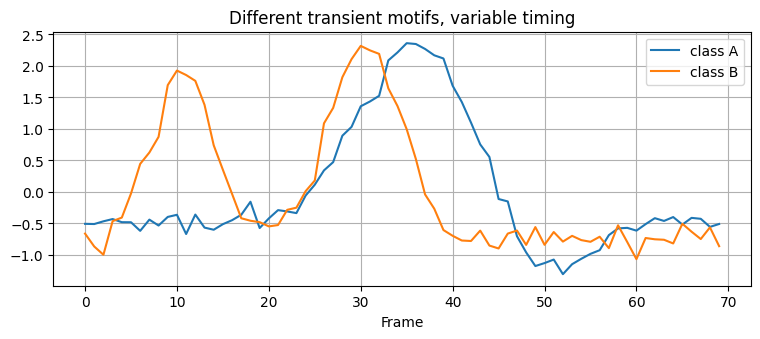

In [15]:
# Two small classes of synthetic transient patterns.
# They undergo random shifts and local duration changes; each sequence has 70 frames.
dtw_rng=np.random.default_rng(52)
SEQ_LEN=70
grid=np.linspace(0,1,SEQ_LEN)

def transient(kind, rng):
    shift=rng.uniform(-0.12,0.12)
    speed=rng.uniform(0.75,1.25)
    u=(grid-shift)/speed
    gauss=lambda center,width: np.exp(-0.5*((u-center)/width)**2)
    if kind==0:
        sig=1.1*gauss(0.48,0.09)-0.40*gauss(0.66,0.065)
    else:
        sig=0.75*gauss(0.31,0.06)+0.85*gauss(0.66,0.07)
    sig=sig+rng.normal(0,0.04,SEQ_LEN)
    return (sig-sig.mean())/(sig.std()+1e-9)

X_dtw_train=np.array([transient(k,dtw_rng) for k in [0,1] for _ in range(20)])
y_dtw_train=np.array([0]*20+[1]*20)
X_dtw_test=np.array([transient(k,dtw_rng) for k in [0,1] for _ in range(12)])
y_dtw_test=np.array([0]*12+[1]*12)
plt.plot(X_dtw_train[0],label='class A');plt.plot(X_dtw_train[20],label='class B');
plt.title('Different transient motifs, variable timing');plt.xlabel('Frame');plt.legend();plt.show()


### C1. Implement constrained DTW distance
For each pair (i,j), compare A[i] with B[j]. The best cumulative cost can arrive from the **upper**, **left** or **diagonal** neighbor. A diagonal band of radius 14 is a pragmatic constraint on unrealistic warping.

The function returns a square root of accumulated squared local differences; it is not a probability or a frequency estimate. This is a teaching implementation (no external DTW package).

In [16]:
def dtw_distance(a, b, radius=None):
    """DTW total squared mismatch, square-rooted; optional diagonal warping band."""
    n,m=len(a),len(b)
    acc=np.full((n+1,m+1),np.inf)
    acc[0,0]=0.0
    if radius is None: radius=max(n,m)
    for i in range(1,n+1):
        for j in range(max(1,i-radius), min(m,i+radius)+1):
            local=(a[i-1]-b[j-1])**2
            acc[i,j]=local+min(acc[i-1,j],acc[i,j-1],acc[i-1,j-1])
    return np.sqrt(acc[n,m])

# Example: same class but differently timed.
a=X_dtw_train[0]; b=X_dtw_train[7]
print('Same-class pair: Euclidean=',round(np.linalg.norm(a-b),2),
      'DTW=',round(dtw_distance(a,b,radius=14),2))


Same-class pair: Euclidean= 13.06 DTW= 2.3


**Alignment matrix:** each cell compares one point from A with one point from B. The low-cost DTW path can move right, down or diagonally, but never backward. Visualize the path for two example sequences.

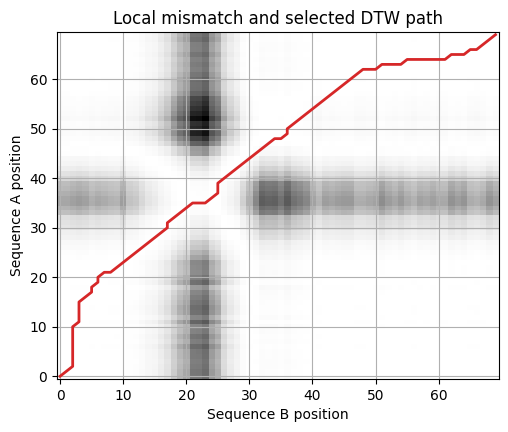

In [17]:
def dtw_path(a, b, radius=14):
    n,m=len(a),len(b)
    acc=np.full((n+1,m+1),np.inf); acc[0,0]=0
    for i in range(1,n+1):
        for j in range(max(1,i-radius),min(m,i+radius)+1):
            acc[i,j]=(a[i-1]-b[j-1])**2+min(acc[i-1,j],acc[i,j-1],acc[i-1,j-1])
    i,j=n,m; path=[]
    while i>0 and j>0:
        path.append((i-1,j-1))
        candidates=[acc[i-1,j-1],acc[i-1,j],acc[i,j-1]]
        choice=int(np.argmin(candidates))
        if choice==0: i,j=i-1,j-1
        elif choice==1: i-=1
        else: j-=1
    return list(reversed(path))

path=dtw_path(a,b)
local_cost=(a[:,None]-b[None,:])**2
plt.figure(figsize=(5.7,4.5))
plt.imshow(local_cost,origin='lower',cmap='Greys',aspect='auto')
plt.plot([q for p,q in path],[p for p,q in path],color='tab:red',lw=2)
plt.xlabel('Sequence B position');plt.ylabel('Sequence A position')
plt.title('Local mismatch and selected DTW path');plt.show()


### C2. Build a nearest-neighbour classifier
For each test transient, find the closest training transient. Compare `np.linalg.norm(a-b)` (fixed alignment) with your DTW distance (flexible alignment). Measure both accuracy and computational time.

In [18]:
def one_nearest_neighbour(train_x, train_y, test_x, distance):
    predictions=[]
    for q in test_x:
        distances=[distance(q,x) for x in train_x]
        predictions.append(train_y[int(np.argmin(distances))])
    return np.array(predictions)

start=perf_counter()
pred_eu=one_nearest_neighbour(X_dtw_train,y_dtw_train,X_dtw_test,lambda a,b:np.linalg.norm(a-b))
time_eu=perf_counter()-start
start=perf_counter()
pred_dtw=one_nearest_neighbour(X_dtw_train,y_dtw_train,X_dtw_test,lambda a,b:dtw_distance(a,b,radius=14))
time_dtw=perf_counter()-start
print('Euclidean 1-NN accuracy:',round(accuracy_score(y_dtw_test,pred_eu),3),'time [s]:',round(time_eu,3))
print('DTW 1-NN accuracy:',round(accuracy_score(y_dtw_test,pred_dtw),3),'time [s]:',round(time_dtw,3))


Euclidean 1-NN accuracy: 0.917 time [s]: 0.005
DTW 1-NN accuracy: 1.0 time [s]: 1.292


**Discussion:** Which method works better here? Is DTW always superior to Euclidean distance? Why constrain warping, and why may DTW be more computationally expensive?

**Suggested answer:** Euclidean compares A[i] directly with B[i]. DTW finds a low-cost monotone alignment and may better match shapes with variable timing. The warping band restricts implausible alignments; it is a modelling choice, not a mathematical necessity. DTW can be slower than pointwise Euclidean distance, especially with many reference sequences.

# D. Final fair-comparison report (about 15 minutes)

Your brief report should contain:

1. **Forecasting:** validation MAE table, selected-model test MAE, and a plot of forecast errors or values.
2. **Fault classification:** validation accuracy/precision/recall/F1, selected-model test confusion matrix, and a threshold trade-off.
3. **DTW:** Euclidean vs DTW accuracy and runtime on the same transient test cases.
4. **Engineering decision:** which simple model would you deploy for each task? Give at least one known or observed **failure mode**, and one **cost/complexity consideration**.

**Controlled comparison checklist:** same prediction time, target, horizon, admissible information, partition, test samples and metrics within each like-for-like comparison. Do not claim that results from different tasks can be ranked together.


In [19]:
# Final engineering summary: these comparisons concern DIFFERENT tasks.
# Do NOT put forecast MAE and fault-classification F1 into one common ranking.
print('Regression validation metrics (smaller MAE is better):')
print(reg_report.round(3).to_string(index=False))
print('\nClassification validation metrics (larger fault F1 is better):')
print(clf_report.round(3).to_string(index=False))
print('\nDTW comparison: classification on a separate transient-motif dataset.')
print('Include costs, error cases, and the validation-selection protocol in your report.')


Regression validation metrics (smaller MAE is better):
              Model   MAE  Fit time [s]
   Ridge / features 2.356         0.003
Boosting / features 2.467         0.131
       Ridge / lags 2.890         0.005
        Persistence 3.230         0.000

Classification validation metrics (larger fault F1 is better):
        Model  Accuracy  Precision  Recall    F1  Fit [s]
     Logistic     0.969      0.909   1.000 0.952    0.027
Random forest     0.958      1.000   0.867 0.929    0.216
     Boosting     0.938      0.962   0.833 0.893    0.089
Decision tree     0.917      0.923   0.800 0.857    0.002
     Majority     0.688      0.000   0.000 0.000    0.001

DTW comparison: classification on a separate transient-motif dataset.
Include costs, error cases, and the validation-selection protocol in your report.


**Suggested report interpretation:** Report the same split, target, horizon, admissible inputs, metrics and samples for each like-for-like comparison. Selecting a threshold on the test set is leakage. Feature and model changes should be separated when attributing a gain. Compare operational costs and failure modes, not accuracy alone.

**Teacher notes:** Synthetic data make qualitative differences observable but should not be treated as evidence about real industrial performance. The regression experiment separates model flexibility from feature choice in its last comparison; a dedicated three-way ablation is required to isolate information versus representation. In the DTW example, the test examples are not used for selecting the warping band; the band is prescribed for pedagogy. For real work, choose radius and other settings on validation only.

## Final message

A useful model comparison is **not just a leaderboard**. Baselines establish a reference, engineered features introduce assumptions, richer models may capture nonlinearities, and DTW offers an alternative shape-similarity route. Only **fair evaluation and engineering constraints** determine whether added complexity is worthwhile.

**Lecture mapping:** 3.E = Sections A/B; 3.F = Section C; 3.G = Section D. Nothing from later RNN/CNN lectures is required.